# Advanced Transport Phenomena

## Practical session 2 - 2D transport and iterative Poisson solvers

from Alberto Cuoci and Adrien Guillonneau

The point of this practical is to extend the 1D explicit Euler scheme from the first practical to two dimensions, and to introduce iterative methods (Jacobi, Gauss-Seidel, SOR) for solving the Poisson equation.

## 0. Python notes for this practical

A NumPy 2D array is created with a shape tuple, `np.zeros((nx, ny))`, and indexed exactly like a MATLAB matrix, `f[i, j]` in place of `f(i,j)`, with the usual difference that indices start at 0.

The boundary conditions below select a segment of the domain using MATLAB expressions like `ny*1/3 : ny*2/3+1`. The general rule for translating a MATLAB range `a(s:e)` into Python is `a[s-1:e]`: shift the start by one, and leave the stop as it is, since a MATLAB inclusive endpoint at position `e` lands exactly on a Python exclusive stop of `e`.

## Advection-diffusion equation in 2D

### 1. Case description

The advection-diffusion equation in 2D, over a rectangular domain of size $L_x \times L_y$:

$$
\frac{\partial f}{\partial t} + u \frac{\partial f}{\partial x} + v \frac{\partial f}{\partial y} = \Gamma \left(\frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}\right)
$$

Along the north ($y=L_y$), south ($y=0$), and west ($x=0$) sides, zero gradient (Neumann) boundary conditions are prescribed:

$$
\frac{\partial f}{\partial n} = 0
$$

Along the east side ($x=L_x$), a Dirichlet condition is prescribed over the central third of the boundary:

$$
f\left(x=L_x;\ y \in \left[\frac{L_y}{3}, \frac{2L_y}{3}\right]\right) = f_{inlet} \qquad\qquad f\left(x=L_x;\ y \in \left[0,\frac{L_y}{3}\right] \cup \left[\frac{2L_y}{3}, L_y\right]\right) = 0
$$

Explicit (forward) Euler in time, centered 2nd order differences in space:

$$
\frac{f_{i,j}^{n+1} - f_{i,j}^{n}}{\Delta t} + u\,\frac{f_{i+1,j}^n - f_{i-1,j}^n}{2h_x} + v\,\frac{f_{i,j+1}^n - f_{i,j-1}^n}{2h_y} = \Gamma\,\frac{f_{i+1,j}^n - 2f_{i,j}^n + f_{i-1,j}^n}{h_x^2} + \Gamma\,\frac{f_{i,j+1}^n - 2f_{i,j}^n + f_{i,j-1}^n}{h_y^2}
$$

The typical solution after a sufficiently large time is a plume of $f$ entering from the central section of the east side, transported along $x$ by advection and spreading in both directions by diffusion.

### 2. Numerical setup

A regular 2D squared grid is considered ($L_x = L_y$, $n_x = n_y$), with $u=-1$ and $v=0$, a uniform velocity field from east to west.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

nx = 33         # number of grid points along x
ny = 33         # number of grid points along y
nstep = 150     # number of time steps
lengthx = 2.0   # domain length along x [m]
lengthy = 2.0   # domain length along y [m]
D = 0.025       # diffusion coefficient [m2/s] GAMMA
u = -1.0        # velocity along x [m/s]
v = 0.0         # velocity along y [m/s]
fin = 1.0       # inlet value of f

hx = lengthx / (nx - 1)   # grid step along x [m]
hy = lengthy / (ny - 1)   # grid step along y [m]

sigma = 0.75                            # safety coefficient
dt_diff = 0.25 * min(hx**2, hy**2) / D   # diffusion stability limit [s]
dt_conv = 4 * D / (u**2 + v**2)          # convection stability limit [s]
dt = sigma * min(dt_diff, dt_conv)       # time step [s]

### 3. Building numerical scheme

The solution array is pre-allocated, and the inlet Dirichlet condition is fixed on the east side. The MATLAB range `ny*1/3 : (ny*2/3+1)` becomes `ny*1//3 - 1 : ny*2//3 + 1` in Python, following the rule from Section 0.

In [2]:
f = np.zeros((nx, ny))       # current numerical solution

j1 = ny * 1 // 3        #           (first index, 1-based)
j2 = ny * 2 // 3 + 1    #        (last index, 1-based, inclusive)
f[nx - 1, j1 - 1:j2] = fin

### 4. Explicit Euler

The interior update follows the same forward Euler pattern as the 1D scheme, applied along both directions at once. As before, `.copy()` is required before overwriting `f`.

In [6]:
def explicit_step_2d(f_old, nx, ny, hx, hy, dt, u, v, D):
    '''One explicit Euler step for the 2D advection-diffusion equation.'''
    f_new = f_old.copy()

    for i in range(1, nx - 1):
        for j in range(1, ny - 1):
            f_new[i, j] = (f_old[i, j]
                           - (0.5 * dt * u / hx) * (f_old[i+1, j] - f_old[i-1, j])
                           - (0.5 * dt * v / hy) * (f_old[i, j+1] - f_old[i, j-1])
                           + (D * dt / hx**2) * (f_old[i+1, j] - 2*f_old[i, j] + f_old[i-1, j])
                           + (D * dt / hy**2) * (f_old[i, j+1] - 2*f_old[i, j] + f_old[i, j-1]))

    # Neumann boundary conditions (south, north, west): left as an exercise below
    #f_new[:, 0]  =  f_old[:, 1]       
    #f_new[:, -1] =  f_old[:, -2]      
    #f_new[0, :]  =  f_old[1, :]

    return f_new

The interior loop above updates every point except the four edges. Three of those edges need a zero-gradient (Neumann) condition, meaning the boundary value equals its nearest interior neighbor from the previous step. The east edge needs nothing here, it is a steady Dirichlet condition already fixed once in Section 3, and a boundary condition that never changes in time never needs to be reapplied.

Complete the three commented lines above, then check: with `u = 0` and `v = 0` (no advection), the field should relax so that every column and row runs flat near the south, north, and west edges, since a zero-gradient condition forces exactly that.

### 5. Bringing it together

In [7]:
def run_advection_diffusion_2d(nx, ny, nstep, lengthx, lengthy, D, u, v, fin):
    hx = lengthx / (nx - 1)
    hy = lengthy / (ny - 1)

    sigma = 0.75
    dt_diff = 0.25 * min(hx**2, hy**2) / D
    dt_conv = 4 * D / (u**2 + v**2)
    dt = sigma * min(dt_diff, dt_conv)
 

    f = np.zeros((nx, ny))
    j1 = ny * 1 // 3
    j2 = ny * 2 // 3 + 1
    f[nx - 1, j1 - 1:j2] = fin

    f_history, t_history = [], []

    t = 0.0
    for m in range(nstep):
        f_history.append(f.copy())
        t_history.append(t)

        f = explicit_step_2d(f, nx, ny, hx, hy, dt, u, v, D)
        t = t + dt

    return {"f_history": f_history, "t_history": t_history, "hx": hx, "hy": hy}

result = run_advection_diffusion_2d(nx=33, ny=33, nstep=150, lengthx=2.0, lengthy=2.0, D=0.025, u=-1.0, v=0.0, fin=1.0)

Running this cell without completing the Neumann boundary conditions in `explicit_step_2d` will not raise an error, but the south, north, and west edges will silently stay at whatever value they last held, instead of following the interior field. This is a case worth remembering: an incomplete boundary condition does not always crash, sometimes it just gives a quietly wrong answer.

### 6. Graphical output

For a 2D field, a color map (`pcolormesh`) is simpler to animate than a 3D surface and carries the same information.

In [8]:
import matplotlib.animation as animation
from IPython.display import HTML

def animate_advection_diffusion_2d(result, lengthx, lengthy, nx, ny):
    xaxis = np.linspace(0, lengthx, nx)
    yaxis = np.linspace(0, lengthy, ny)

    fig, ax = plt.subplots(figsize=(6, 5))
    mesh = ax.pcolormesh(xaxis, yaxis, result["f_history"][0].T, vmin=0, vmax=1.25, shading="auto")
    fig.colorbar(mesh, ax=ax, label="f")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    title = ax.set_title("")

    def update(frame):
        mesh.set_array(result["f_history"][frame].T.ravel())
        title.set_text(f"time = {result['t_history'][frame]:.3f} s")
        return mesh, title

    anim = animation.FuncAnimation(fig, update, frames=len(result["f_history"]),
                                    interval=60, blit=False)
    plt.close(fig)
    return anim

anim = animate_advection_diffusion_2d(result, lengthx=2.0, lengthy=2.0, nx=33, ny=33)
HTML(anim.to_jshtml())

### Exercises

1. Complete the Neumann boundary conditions in Section 4, then check them with the flat-field test described there.
2. Analyze the effect of the diffusion coefficient on the solution.
3. Calculate the solution corresponding to the following new boundary conditions along the east side:

$$
f\left(x=L_x;\ y \in \left[\frac{L_y}{5}, \frac{2L_y}{5}\right]\cup\left[\frac{3L_y}{5}, \frac{4L_y}{5}\right]\right) = f_{inlet}
$$
$$
f\left(x=L_x;\ y \in \left[0,\frac{L_y}{5}\right] \cup \left[\frac{2L_y}{5}, \frac{3L_y}{5}\right] \cup \left[\frac{4L_y}{5}, L_y\right]\right) = 0
$$
4. Implement a FDS and a BDS for the advection term in this 2D case and compare the results.

## Poisson equation in 2D

### 1. Case description

The Poisson equation on a 2D rectangular domain, solved with the Successive Over-Relaxation method:

$$
\frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2} = S(x,y)
$$

Using standard finite differences and, for equal grid steps ($h_x=h_y=h$):

$$
f_{i,j} = \frac{1}{4}\left(f_{i+1,j}+f_{i-1,j}+f_{i,j+1}+f_{i,j-1} - h^2 S_{i,j}\right)
$$

**Jacobi**: solve for $f_{i,j}$ using only old values on the right hand side. Simple, but many iterations are needed. The residual, which should be zero at steady state, measures how far a candidate solution is from satisfying the equation:

$$
R_{i,j}^{\alpha} = \frac{f_{i+1,j}^{\alpha} - 2f_{i,j}^{\alpha} + f_{i-1,j}^{\alpha}}{h_x^2} + \frac{f_{i,j+1}^{\alpha} - 2f_{i,j}^{\alpha} + f_{i,j-1}^{\alpha}}{h_y^2} - S_{i,j}^{\alpha}
$$

**Gauss-Seidel**: the same idea, but using new values as soon as they become available, converges markedly faster.

**SOR**: pushes the Gauss-Seidel correction further at each step, by a factor $\beta$:

$$
f_{i,j}^{\alpha+1} = \left[\frac{1}{2(h_x^2+h_y^2)}\left(h_y^2 f_{i+1,j}^{\alpha} + h_y^2 f_{i-1,j}^{\alpha+1} + h_x^2 f_{i,j+1}^{\alpha} + h_x^2 f_{i,j-1}^{\alpha+1} - h_x^2 h_y^2 S_{i,j}^{\alpha}\right)\right]\beta + f_{i,j}^{\alpha}(1-\beta)
$$

$\beta=1$ recovers Gauss-Seidel exactly. $1 < \beta < 2$ is required for SOR to accelerate convergence; $\beta=1.5$ is usually a good starting value.

### 2. Numerical setup

In [9]:
lengthx = 2.0          # domain length along x [m]
lengthy = 2.0          # domain length along y [m]
nx = 39                # number of grid points along x
ny = 39                # number of grid points along y
max_iterations = 5000  # max number of iterations
beta = 1.0             # SOR coefficient (1 means Gauss-Seidel)
threshold = 0.001      # residual threshold

hx = lengthx / (nx - 1)   # grid step along x [m]
hy = lengthy / (ny - 1)   # grid step along y [m]

f = np.zeros((nx, ny))    # current solution
S = np.zeros((nx, ny))    # source term

j1 = ny * 1 // 3
j2 = ny * 2 // 3
f[0, j1 - 1:j2] = 1.0     # Dirichlet condition, west side

### 3. Iteration loop

The SOR formula above updates every interior point, using the most recent values available, and the residual measures how close the current field is to a solution. Both are left to complete: the formula for `f[i, j]` is a direct translation of the equation in Section 7, and the residual follows the same pattern as the update, but with the original, undivided Laplacian.

In [10]:
def run_poisson_2d_sor(lengthx, lengthy, nx, ny, max_iterations, beta, threshold):
    hx = lengthx / (nx - 1)
    hy = lengthy / (ny - 1)

    f = np.zeros((nx, ny))
    S = np.zeros((nx, ny))
    j1 = ny * 1 // 3
    j2 = ny * 2 // 3
    f[0, j1 - 1:j2] = 1.0

    tot_res = []

    for l in range(max_iterations):

        for i in range(1, nx - 1):
            for j in range(1, ny - 1):
                #pass
                # f[i, j] = ...   # SOR update, see Section 7
                f[i, j] = (beta / (2*(hx**2 + hy**2))* ((f[i+1, j] + f[i-1, j]) * hy**2+ (f[i, j+1] + f[i, j-1]) * hx**2- hx**2 * hy**2 * S[i, j])+ (1.0- beta) * f[i, j])
                
        res = 0.0
        for i in range(1, nx - 1):
            for j in range(1, ny - 1):
                #pass
                # res += ...      # residual at (i, j), see Section 7
                res += abs((f[i+1, j]- 2*f[i, j] + f[i-1, j]) / hx**2 + (f[i, j+1]- 2*f[i, j] + f[i, j-1]) / hy**2- S[i, j])

        #raise NotImplementedError("Section 9: complete the SOR update and the residual above, then remove this line")

        tot_res.append(res / ((nx-2) * (ny-2)))
        if l % 25 == 0:
            print(f"Iteration: {l}, Residual: {tot_res[-1]:.6e}")

        if tot_res[-1] < threshold:
            break

    return {"f": f, "tot_res": tot_res, "hx": hx, "hy": hy}

result_poisson = run_poisson_2d_sor(lengthx=2.0, lengthy=2.0, nx=39, ny=39,
                                     max_iterations=5000, beta=1.0, threshold=0.001)

Iteration: 0, Residual: 2.461164e+00
Iteration: 25, Residual: 5.700917e-01
Iteration: 50, Residual: 3.916688e-01
Iteration: 75, Residual: 3.005132e-01
Iteration: 100, Residual: 2.406095e-01
Iteration: 125, Residual: 1.968016e-01
Iteration: 150, Residual: 1.628521e-01
Iteration: 175, Residual: 1.356528e-01
Iteration: 200, Residual: 1.134381e-01
Iteration: 225, Residual: 9.508929e-02
Iteration: 250, Residual: 7.983144e-02
Iteration: 275, Residual: 6.709104e-02
Iteration: 300, Residual: 5.642434e-02
Iteration: 325, Residual: 4.747789e-02
Iteration: 350, Residual: 3.996500e-02
Iteration: 375, Residual: 3.365039e-02
Iteration: 400, Residual: 2.833952e-02
Iteration: 425, Residual: 2.387068e-02
Iteration: 450, Residual: 2.010901e-02
Iteration: 475, Residual: 1.694173e-02
Iteration: 500, Residual: 1.427435e-02
Iteration: 525, Residual: 1.202762e-02
Iteration: 550, Residual: 1.013495e-02
Iteration: 575, Residual: 8.540403e-03
Iteration: 600, Residual: 7.196913e-03
Iteration: 625, Residual: 6.06

### 4. Graphical output

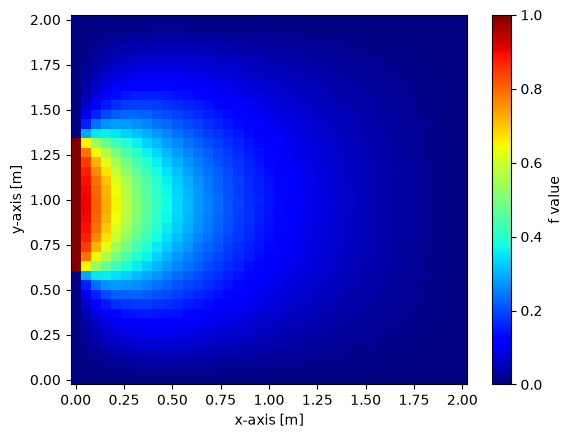

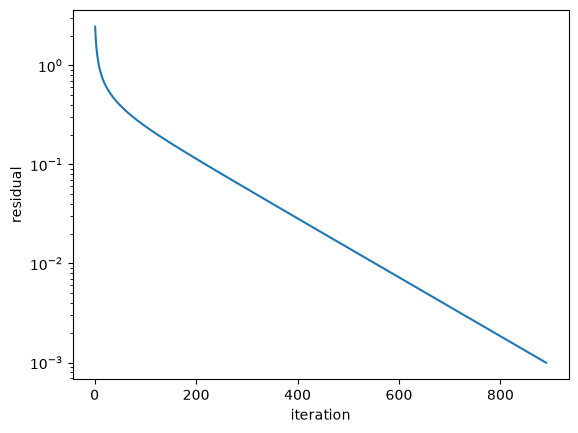

In [11]:
xaxis = np.linspace(0, lengthx, nx)
yaxis = np.linspace(0, lengthy, ny)

plt.figure()
plt.pcolormesh(xaxis, yaxis, result_poisson["f"].T, shading="auto", cmap="jet")
plt.colorbar(label="f value")
plt.xlabel("x-axis [m]")
plt.ylabel("y-axis [m]")
plt.show()

plt.figure()
plt.semilogy(range(1, len(result_poisson["tot_res"])+1), result_poisson["tot_res"])
plt.xlabel("iteration")
plt.ylabel("residual")
plt.show()

### Exercises

1. Identify the optimal value of $\beta$, the value which minimizes the number of iterations.
2. Demonstrate that the numerical discretization adopted is 2nd order accurate in space.
3. Solve a new case, in which the boundary conditions are $f=0$ everywhere (on the west side too) and the source term has the following expression:

$$
S(x,y) = (x-1)^2 + (y-1)^2
$$